# SHL Grammar Scoring Engine: spoken audio to grammar score (0-5)

**Task.** Given a 45-60 s speech clip, predict a continuous MOS-Likert grammar score in [0, 5].
Train: 769 clips, test: 216 clips. Metrics: Pearson correlation and RMSE.

## Report

### Approach in one paragraph
I represent every clip in two complementary ways. **(a) Text side:** I transcribe the audio with Whisper (`small`, via faster-whisper); from the transcript and Whisper's confidence signals I build 14 numeric fluency/structure features and a DeBERTa-v3-base mean-pooled embedding. **(b) Acoustic side:** I pass the raw audio through three frozen self-supervised speech encoders (wav2vec2-base-960h, WavLM-base-plus, HuBERT-base) and take one intermediate-layer embedding from each (mean + standard deviation over time). Each representation feeds a standardised Ridge regressor, and my final score is `0.8 * mean(3 acoustic Ridge) + 0.2 * text Ridge`, clipped to [0, 5].

### Pipeline
```
audio (.wav, 16 kHz)
 |-- Whisper small -> transcript + word timestamps + confidences
 |      |-- 14 numeric features (speech rate, pauses, logprob, TTR, ...)
 |      |-- DeBERTa-v3-base embedding (mean-pooled)  --> Ridge (text model)
 |
 |-- wav2vec2 L8 / WavLM L10 / HuBERT L10  (mean+std pooled) + numeric features
 |                                                --> 3 x Ridge --> average (acoustic model)
 v
final = 0.8 * acoustic + 0.2 * text  -> clip(0, 5)
```

### Preprocessing
* The audio is already 16 kHz mono, so I only average the channels if a clip turns out to be stereo. I do not trim anything.
* For Whisper I force English, switch the VAD filter on, set `condition_on_previous_text=False` and ask for word timestamps. I cache the transcripts in `transcripts.csv`.
* I key every feature by **(split, filename)**. Train and test reuse many of the same file names with *different* audio, so keying by file name alone silently mixes them up (a bug I hit and fixed during development).
* I standardise features inside each CV fold / final fit (`StandardScaler` is part of the pipeline), so scaling does not leak information from the validation fold.

### Why I chose this design (what I learned during development)
* Text-only models are limited: Whisper normalises grammar and removes fillers (my `fillers` feature is ~0), so many grammar errors never reach the transcript.
* Whisper's own confidence (`mean_logprob`, `max_no_speech`) was the strongest numeric signal, which suggests the score correlates with how clearly and fluently the person speaks.
* Intermediate layers of the speech encoders (layer 8-10 of 12) carried the most signal; mean + std pooling beat mean pooling; averaging three different encoders beat any single one.
* Things I tried that did **not** help and that I dropped: TF-IDF features, roberta-large / concatenating several text encoders, SVR instead of Ridge, a 4th acoustic encoder (wavlm-large), cropping/augmenting training clips to 45 s, replacing absolute pause features with rates.

### Development results (from my experiment log; the cells below recompute the final pipeline)
| Model (5-fold CV on train) | RMSE | Pearson |
|---|---|---|
| Predict the mean (baseline) | ~1.24 | 0 |
| roberta-base + numeric, Ridge | 0.774 | 0.780 |
| DeBERTa-v3 + numeric, Ridge | 0.732 | 0.807 |
| Numeric features only, LightGBM | 0.830 | 0.742 |
| wav2vec2 L8, mean+std, Ridge | 0.583 | 0.883 |
| **Final blend (this notebook)** | **~0.53** | **~0.91** |

The public leaderboard score of my final submission is **0.3746** (the board ranks lower as better; the exact formula that combines Pearson and RMSE is not published).

In [16]:
# ---------------- Imports ----------------
import os, re, sys, glob, warnings, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GroupKFold   # KFold = normal CV, GroupKFold = CV that keeps clusters together
from sklearn.linear_model import Ridge                  # the regression model used everywhere in the final pipeline
from sklearn.preprocessing import StandardScaler        # rescales every feature to zero mean / unit variance
from sklearn.pipeline import make_pipeline              # chains scaler + model so the scaler is fitted only on training folds
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans                      # only used for the grouped-CV robustness check
from scipy.stats import pearsonr                        # Pearson correlation = one of the two competition metrics
import lightgbm as lgb                                  # only used for the "numeric features only" ablation row

warnings.filterwarnings("ignore")   # keep the notebook output readable
SEED = 42                           # fixed seed so every run gives the same numbers
np.random.seed(SEED)
# On Kaggle, files that should survive the session must be written to /kaggle/working; elsewhere use the current folder
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

def pip_install(*pkgs):
    # small helper: install a library from inside the notebook (used only when a model has to be run)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

def find_cache(fname):
    # look for a cached artefact (transcripts, embeddings, ...) in the working dir first,
    # then in any attached Kaggle dataset; returns None if it does not exist anywhere
    p = f"{WORK}/{fname}"
    if os.path.exists(p):
        return p
    hits = glob.glob(f"/kaggle/input/**/{fname}", recursive=True)
    return hits[0] if hits else None

# the two competition metrics; predictions are clipped to the valid score range [0, 5] before RMSE
def rmse(y, p): return mean_squared_error(y, np.clip(p, 0, 5)) ** 0.5
def pear(y, p): return pearsonr(y, p)[0]

In [17]:
# PyAV: audio-decoding library that faster-whisper relies on; pinned to one version for reproducibility
!pip install "av==15.1.0"

## 1. Data

train: (769, 3) test: (216, 3)
file names that appear in BOTH train and test: 212 (different audio, so every lookup must use (split, filename))
count    769.000
mean       3.313
std        1.239
min        0.000
25%        2.500
50%        3.000
75%        4.000
max        5.000


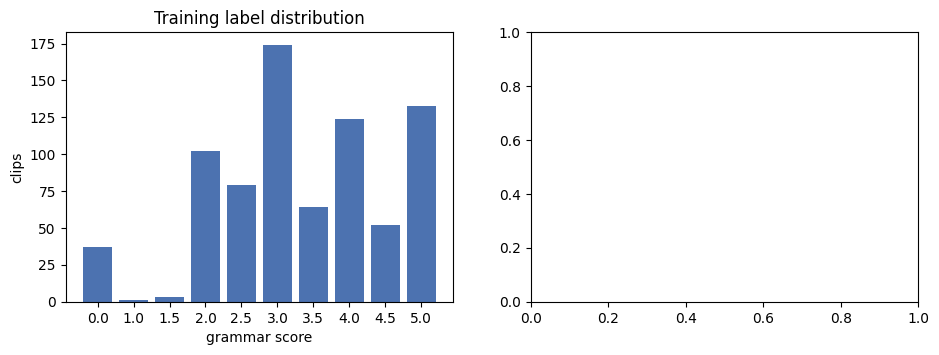

In [18]:
# locate the competition folder automatically (works for any attached dataset name)
train_csv = glob.glob("/kaggle/input/**/train.csv", recursive=True) or glob.glob("./**/train.csv", recursive=True)
DATA = os.path.dirname(train_csv[0])
train = pd.read_csv(f"{DATA}/train.csv")   # columns: filename, label
test = pd.read_csv(f"{DATA}/test.csv")     # the labels in test.csv are random placeholders (-1) and are never used
# audio files live in <DATA>/train/ and <DATA>/test/; store the full path of each clip
train["path"] = DATA + "/train/" + train.filename
test["path"] = DATA + "/test/" + test.filename
ytr = train.label.values                   # training targets, used by every model below
print("train:", train.shape, "test:", test.shape)
# IMPORTANT data quirk: many file names exist in both folders but belong to different audio,
# so every lookup in this notebook uses the pair (split, filename), never the file name alone
print("file names that appear in BOTH train and test:", len(set(train.filename) & set(test.filename)),
      "(different audio, so every lookup must use (split, filename))")

# label distribution plot (left panel); the right panel stays empty and is not used
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
vc = train.label.value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color="#4C72B0")
ax[0].set_title("Training label distribution"); ax[0].set_xlabel("grammar score"); ax[0].set_ylabel("clips")
print(train.label.describe().round(3).to_string())

## 2. Transcription (Whisper small, cached)
I cache the transcripts in `transcripts.csv`. If the file is present I reuse it and only transcribe the clips that are missing (a GPU is needed only in that case).

In [19]:
def get_whisper():
    # load the Whisper "small" model on the GPU in half precision (fast); only called if some transcript is missing
    pip_install("faster-whisper")
    from faster_whisper import WhisperModel
    return WhisperModel("small", device="cuda", compute_type="float16")

def transcribe(model, path):
    # transcribe one clip and return the transcript plus timing/confidence statistics
    segs, info = model.transcribe(path,
                                  language="en",                      # force English (the task is English grammar)
                                  beam_size=5,                        # beam search for a more accurate transcript
                                  word_timestamps=True,               # needed to measure pauses and speech rate
                                  vad_filter=True,                    # skip long silences (reduces hallucinated text)
                                  condition_on_previous_text=False)   # avoids repetition loops across segments
    text, words, lp, nsp = [], [], [], []
    for s in segs:
        text.append(s.text.strip())
        lp.append(s.avg_logprob)          # Whisper's average log-probability of the segment (confidence)
        nsp.append(s.no_speech_prob)      # probability that the segment contains no speech
        words += [(w.start, w.end) for w in (s.words or [])]   # (start, end) time of every word
    # gap between the end of one word and the start of the next = silence between words
    gaps = [words[i + 1][0] - words[i][1] for i in range(len(words) - 1)]
    return dict(text=" ".join(text), n_words=len(words), audio_dur=info.duration,
                speech_start=words[0][0] if words else np.nan,    # when the person starts speaking
                speech_end=words[-1][1] if words else np.nan,     # when the last word ends
                mean_logprob=np.mean(lp) if lp else np.nan,
                max_no_speech=max(nsp) if nsp else np.nan,
                n_pauses=sum(g > 0.5 for g in gaps),              # a "pause" = silence longer than 0.5 s
                total_pause=sum(g for g in gaps if g > 0.5))      # total seconds spent in pauses

# list of every clip (train first, then test) with its split
all_files = pd.concat([train.assign(split="train"), test.assign(split="test")])[["filename", "path", "split"]]
# reuse cached transcripts if available ...
p = find_cache("transcripts.csv")
T = pd.read_csv(p) if p else pd.DataFrame(columns=["filename", "split"])
# ... and find out which (split, filename) pairs are still missing
have = set(zip(T.split, T.filename))
todo = all_files[[(s, f) not in have for s, f in zip(all_files.split, all_files.filename)]]
print("cached transcripts:", len(T), "| to transcribe:", len(todo))
if len(todo):                                   # only runs when something is missing (needs a GPU)
    from tqdm.auto import tqdm
    wm = get_whisper()
    new = [dict(filename=r.filename, split=r.split, **transcribe(wm, r.path)) for r in tqdm(list(todo.itertuples()))]
    T = pd.concat([T, pd.DataFrame(new)], ignore_index=True)
T["text"] = T.text.fillna("")                   # clips with no recognised speech get an empty string
T.to_csv(f"{WORK}/transcripts.csv", index=False)   # save so the next run does not need Whisper
assert len(T) == len(train) + len(test), len(T)    # sanity check: one row per clip
print(T.split.value_counts().to_dict())
print(T.text.iloc[0][:300])                     # eyeball one transcript

cached transcripts: 985 | to transcribe: 0
{'train': 769, 'test': 216}
The playground is very, very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of play, because once it's in it and the other person will have to push, and meagre rounds, which was kind of funny, and


## 3. Numeric features from the transcript
From each transcript I compute speech rate, pause statistics, Whisper confidence and sentence/vocabulary statistics. Note that the `fillers` feature is almost always 0 because Whisper removes filler words.

numeric features: 14 | train rows: 769 | test rows: 216


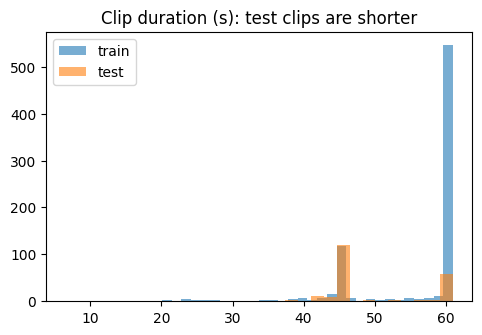

In [20]:
FILLERS = {"um", "uh", "er", "erm", "hmm", "ah"}   # filler words (Whisper usually removes them, so this stays ~0)

def feats(r):
    # build the 14 numeric fluency / structure features for one clip (r = one row of T)
    words = re.findall(r"[a-z']+", r.text.lower())                       # lower-cased word list
    sents = [s for s in re.split(r"[.!?]+", r.text) if s.strip()]         # crude sentence split on . ! ?
    dur = (r.speech_end - r.speech_start) if r.n_words > 0 else np.nan    # time between first and last word
    return dict(
        n_words=r.n_words, speech_start=r.speech_start, speech_end=r.speech_end,
        wpm=r.n_words / dur * 60 if dur and dur > 0 else 0,                       # speaking rate (words per minute)
        speech_ratio=dur / r.audio_dur if dur and r.audio_dur else 0,             # share of the clip that contains speech
        n_pauses=r.n_pauses, total_pause=r.total_pause,                           # pause count and total pause time
        mean_logprob=r.mean_logprob, max_no_speech=r.max_no_speech,               # Whisper confidence signals
        n_sents=len(sents), avg_sent_len=len(words) / max(len(sents), 1),         # sentence count and average length
        ttr=len(set(words)) / max(len(words), 1),                                 # type-token ratio = vocabulary diversity
        fillers=sum(w in FILLERS for w in words),                                 # number of filler words
        repeats=sum(a == b for a, b in zip(words, words[1:])))                    # immediate word repetitions ("the the")

F = pd.DataFrame([feats(r) for r in T.itertuples()]).fillna(0)   # one row per clip, missing values -> 0

# row lookup keyed by (split, filename)
# idx maps (split, filename) -> row number in T, F and in all cached embedding arrays
idx = {(s, f): i for i, (s, f) in enumerate(zip(T.split, T.filename))}
rows_tr = [idx[("train", f)] for f in train.filename]   # row numbers of the training clips, in train.csv order
rows_te = [idx[("test", f)] for f in test.filename]     # row numbers of the test clips, in test.csv order
Ftr, Fte = F.values[rows_tr], F.values[rows_te]         # numeric features split into train / test matrices
print("numeric features:", F.shape[1], "| train rows:", len(rows_tr), "| test rows:", len(rows_te))

# plot: clip duration of train vs test (shows the train/test shift discussed in the limitations)
fig2, ax2 = plt.subplots(figsize=(5.5, 3.5))
ax2.hist(T.audio_dur[T.split == "train"], bins=30, alpha=.6, label="train")
ax2.hist(T.audio_dur[T.split == "test"], bins=30, alpha=.6, label="test")
ax2.set_title("Clip duration (s): test clips are shorter"); ax2.legend(); plt.show()

## 4. Text embedding (DeBERTa-v3-base, mean-pooled, cached)

In [21]:
def embed_text(texts, name="microsoft/deberta-v3-base", maxlen=384, bs=16):
    # turn each transcript into one 768-dim vector with DeBERTa-v3 (frozen, no fine-tuning)
    import torch
    pip_install("sentencepiece")   # tokenizer dependency of DeBERTa-v3
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(name)
    enc = AutoModel.from_pretrained(name).cuda().eval()   # eval() = inference mode
    out = []
    with torch.no_grad():                                 # no gradients needed, saves memory
        for i in range(0, len(texts), bs):                # process the transcripts in small batches
            b = tok(list(texts[i:i + bs]), padding=True, truncation=True, max_length=maxlen,
                    return_tensors="pt").to("cuda")
            h = enc(**b).last_hidden_state                # one vector per token
            m = b["attention_mask"].unsqueeze(-1)         # mask so padding tokens are ignored
            out.append(((h * m).sum(1) / m.sum(1)).float().cpu().numpy())   # mean over the real tokens
    del enc
    return np.vstack(out)

p = find_cache("emb_deberta-v3-base.npy")
E_text = np.load(p) if p else np.zeros((0, 768))      # reuse cached embeddings if available
if len(E_text) < len(T):                      # compute only the rows that are not cached yet
    E_text = np.vstack([E_text, embed_text(T.text.values[len(E_text):])]) if len(E_text) else embed_text(T.text.values)
    np.save(f"{WORK}/emb_deberta-v3-base.npy", E_text)   # cache for the next run
assert E_text.shape[0] == len(T), E_text.shape           # sanity check: one embedding per clip, same order as T
print("text embedding:", E_text.shape)

text embedding: (985, 768)


## 5. Acoustic embeddings (wav2vec2, WavLM, HuBERT; frozen, mean + std over time, cached)
I store layers 4, 6, 8 and 10 for each encoder. My final model uses the best layer per encoder that I found in development (wav2vec2 L8, WavLM L10, HuBERT L10).

In [22]:
LAY = [4, 6, 8, 10]    # transformer layers whose output I store (intermediate layers carry most acoustic/fluency information)
# encoder -> the layer used in the final model (picked during development by comparing CV scores)
ACOUSTIC = {"facebook/wav2vec2-base-960h": 8, "microsoft/wavlm-base-plus": 10, "facebook/hubert-base-ls960": 10}

def extract_acoustic(name, keys):
    # run one frozen speech encoder over the audio of the given (split, filename) keys;
    # for every clip and every layer in LAY return the mean and the std of the frame vectors over time
    import torch, soundfile as sf
    from tqdm.auto import tqdm
    from transformers import AutoFeatureExtractor, AutoModel
    fe = AutoFeatureExtractor.from_pretrained(name)        # normalises the waveform the way the model expects
    m = AutoModel.from_pretrained(name).cuda().eval()
    mu, sd = [], []
    with torch.no_grad():
        for s, f in tqdm(keys, desc=name):
            wav, sr = sf.read(f"{DATA}/{s}/{f}", dtype="float32")   # read the 16 kHz waveform
            if wav.ndim > 1: wav = wav.mean(1)                      # stereo -> mono
            x = fe(wav, sampling_rate=16000, return_tensors="pt").input_values.cuda()
            hs = m(x, output_hidden_states=True).hidden_states      # outputs of all layers
            mu.append(np.stack([hs[l][0].mean(0).cpu().numpy() for l in LAY]))   # average over time = "how much"
            sd.append(np.stack([hs[l][0].std(0).cpu().numpy() for l in LAY]))    # std over time = "how much it varies"
    del m
    return np.stack(mu), np.stack(sd)   # shapes: (n_clips, len(LAY), hidden_size)

keys_all = list(zip(T.split, T.filename))   # (split, filename) of every clip, in the same order as T
AC = {}                                     # encoder name -> (mean embeddings, std embeddings)
for name in ACOUSTIC:
    short = name.split("/")[-1]
    p = find_cache(f"ac_{short}.npz")       # cached embeddings of this encoder, if any
    if p:
        z = np.load(p); mu, sd = z["mu"], z["sd"]
    else:
        mu = sd = None
    n_have = 0 if mu is None else len(mu)   # how many clips are already cached
    if n_have < len(T):                       # extract only missing rows (same order as T)
        mu2, sd2 = extract_acoustic(name, keys_all[n_have:])
        mu = mu2 if mu is None else np.concatenate([mu, mu2])
        sd = sd2 if sd is None else np.concatenate([sd, sd2])
        np.savez(f"{WORK}/ac_{short}.npz", mu=mu, sd=sd)   # cache for the next run
    assert mu.shape[0] == len(T), (short, mu.shape)         # sanity check: one embedding per clip
    AC[name] = (mu, sd)
    print(short, mu.shape)

wav2vec2-base-960h (985, 4, 768)
wavlm-base-plus (985, 4, 768)
hubert-base-ls960 (985, 4, 768)


## 6. Models and cross-validation
Every model I train is `StandardScaler -> Ridge(alpha=300)` on `[numeric features | embedding]`. I evaluate with 5-fold CV on the training set (shuffled, seed 42) and clip all predictions to [0, 5].

Mean-prediction baseline RMSE: 1.238
                                                   CV RMSE  CV Pearson
Numeric only (LightGBM)                              0.830       0.742
Text: DeBERTa + numeric (Ridge)                      0.732       0.807
Acoustic: wav2vec2-base-960h L8 + numeric (Ridge)    0.583       0.883
Acoustic: wavlm-base-plus L10 + numeric (Ridge)      0.570       0.888
Acoustic: hubert-base-ls960 L10 + numeric (Ridge)    0.565       0.890
Acoustic ensemble (3 encoders)                       0.545       0.899
FINAL: 0.8 acoustic + 0.2 text                       0.531       0.908


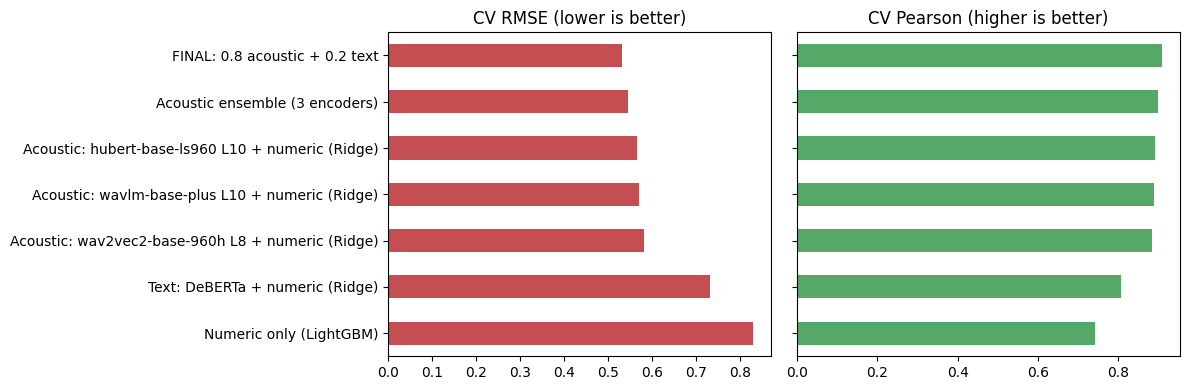

In [23]:
kf = KFold(5, shuffle=True, random_state=SEED)                     # 5-fold CV on the training set
ridge300 = lambda: make_pipeline(StandardScaler(), Ridge(alpha=300))   # scaler + Ridge; alpha=300 = strong regularisation
# LightGBM is used only for the "numeric features only" ablation row (small trees because the data is small)
gbm = lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=20,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                random_state=SEED, verbose=-1)

def cv_oof(make_model, X):
    # out-of-fold predictions: every training clip is predicted by a model that never saw that clip
    oof = np.zeros(len(ytr))
    for a, b in kf.split(X):                                   # a = training part, b = validation part
        oof[b] = make_model().fit(X[a], ytr[a]).predict(X[b])
    return oof.clip(0, 5)

def acoustic_X(name):
    # feature matrix of one acoustic encoder = [14 numeric features | mean embedding | std embedding] of its chosen layer
    mu, sd = AC[name]; j = LAY.index(ACOUSTIC[name])
    return np.hstack([F.values, mu[:, j], sd[:, j]])

X_text = np.hstack([F.values, E_text])                  # text model input: numeric features + DeBERTa embedding
X_ac = {n: acoustic_X(n) for n in ACOUSTIC}             # one input matrix per acoustic encoder
W_AC, W_TXT = 0.8, 0.2                                  # final blend weights (acoustic / text)

# ---- ablation: out-of-fold predictions of every component, then of the blends ----
oof = {}
oof["Numeric only (LightGBM)"] = cv_oof(gbm, Ftr)
oof["Text: DeBERTa + numeric (Ridge)"] = cv_oof(ridge300, X_text[rows_tr])
for n in ACOUSTIC:
    oof[f"Acoustic: {n.split('/')[-1]} L{ACOUSTIC[n]} + numeric (Ridge)"] = cv_oof(ridge300, X_ac[n][rows_tr])
ac_keys = [k for k in oof if k.startswith("Acoustic:")]
oof["Acoustic ensemble (3 encoders)"] = np.mean([oof[k] for k in ac_keys], axis=0)    # simple average of the 3 encoders
oof["FINAL: 0.8 acoustic + 0.2 text"] = W_AC * oof["Acoustic ensemble (3 encoders)"] + W_TXT * oof["Text: DeBERTa + numeric (Ridge)"]

# table of CV RMSE / Pearson for every row above
ablation = pd.DataFrame({"CV RMSE": {k: rmse(ytr, v) for k, v in oof.items()},
                         "CV Pearson": {k: pear(ytr, v) for k, v in oof.items()}}).round(3)
print("Mean-prediction baseline RMSE:", round(float(np.std(ytr)), 3))   # RMSE of always predicting the mean = std of the labels
display(ablation) if "display" in globals() else print(ablation)       # nicer table in Jupyter, plain print otherwise

# bar charts of the ablation table (left: RMSE, lower is better; right: Pearson, higher is better)
fig3, ax3 = plt.subplots(1, 2, figsize=(12, 4))
ablation["CV RMSE"].plot.barh(ax=ax3[0], color="#C44E52"); ax3[0].set_title("CV RMSE (lower is better)")
ablation["CV Pearson"].plot.barh(ax=ax3[1], color="#55A868"); ax3[1].set_title("CV Pearson (higher is better)")
ax3[1].set_yticklabels([]); plt.tight_layout(); plt.show()

### Robustness check: cluster-grouped CV
The dataset has no speaker IDs. If one speaker has several clips, random CV can be optimistic. As a proxy I cluster the wav2vec2 embeddings (60 clusters) and keep each cluster inside a single fold.

In [24]:
# cluster the clips by their (scaled) wav2vec2 layer-4 embedding; clips of the same speaker/recording setup
# should end up in the same cluster, so a cluster is never split between training and validation
mu_w = AC["facebook/wav2vec2-base-960h"][0][:, 0]
Z = StandardScaler().fit_transform(mu_w)
grp = KMeans(60, n_init=5, random_state=SEED).fit_predict(Z[rows_tr])   # cluster id of every training clip
gkf = GroupKFold(5)                                                      # CV that keeps each cluster in one fold

def oof_group(make_model, X):
    # same as cv_oof, but the folds respect the clusters
    o = np.zeros(len(ytr))
    for a, b in gkf.split(X, ytr, grp):
        o[b] = make_model().fit(X[a], ytr[a]).predict(X[b])
    return o.clip(0, 5)

# rebuild the final blend under grouped CV and compare with random CV
g_ac = np.mean([oof_group(ridge300, X_ac[n][rows_tr]) for n in ACOUSTIC], axis=0)
g_tx = oof_group(ridge300, X_text[rows_tr])
g_final = W_AC * g_ac + W_TXT * g_tx
print(f"random 5-fold CV : RMSE={rmse(ytr, oof['FINAL: 0.8 acoustic + 0.2 text']):.3f}  Pearson={pear(ytr, oof['FINAL: 0.8 acoustic + 0.2 text']):.3f}")
print(f"cluster-grouped  : RMSE={rmse(ytr, g_final):.3f}  Pearson={pear(ytr, g_final):.3f}")

random 5-fold CV : RMSE=0.531  Pearson=0.908
cluster-grouped  : RMSE=0.553  Pearson=0.900


## 7. Final fit, training RMSE and diagnostics

TRAINING RMSE (fit on all train, evaluated on train): 0.3495
TRAINING Pearson                                    : 0.9641
5-fold CV RMSE / Pearson (honest estimate)          : 0.5308 / 0.9076
The gap between train and CV RMSE shows the model fits the training set more tightly than unseen data.


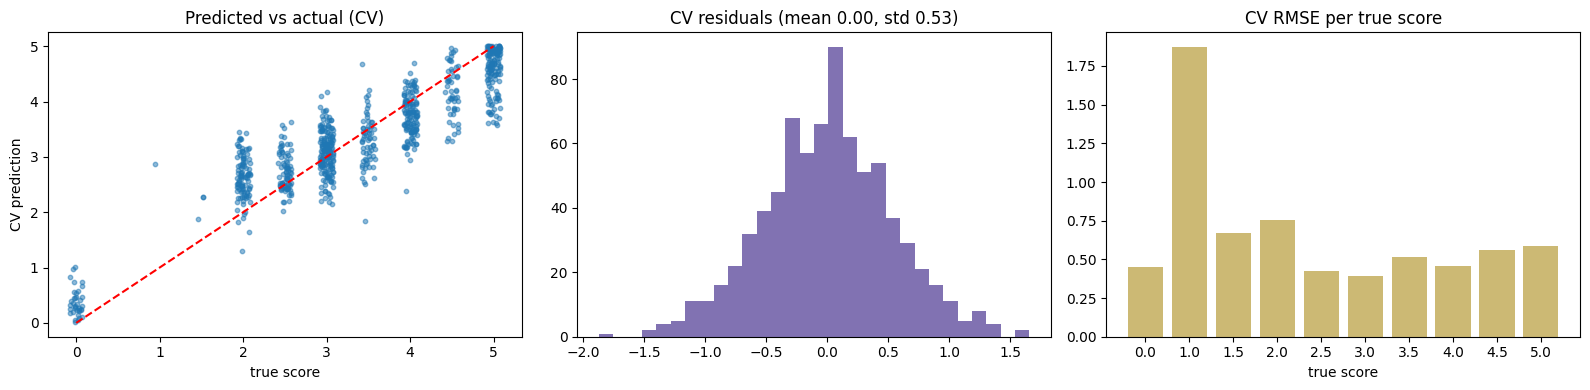

Test prediction summary:
count    216.000
mean       3.323
std        0.758
min        1.718
25%        2.734
50%        3.237
75%        3.768
max        5.000


In [25]:
# ---- final models: fit on ALL 769 training clips ----
fit_ac = [ridge300().fit(X_ac[n][rows_tr], ytr) for n in ACOUSTIC]   # one Ridge per acoustic encoder
fit_tx = ridge300().fit(X_text[rows_tr], ytr)                        # one Ridge for the text model

def predict(rows):
    # final prediction = 0.8 * average of the 3 acoustic Ridge + 0.2 * text Ridge, clipped to [0, 5]
    ac = np.mean([m.predict(X_ac[n][rows]) for m, n in zip(fit_ac, ACOUSTIC)], axis=0)
    return (W_AC * ac + W_TXT * fit_tx.predict(X_text[rows])).clip(0, 5)

pred_tr = predict(rows_tr)                          # predictions on the training clips (for the compulsory training RMSE)
pred_te = predict(rows_te)                          # predictions on the test clips (these go into the submission file)
cv_final = oof["FINAL: 0.8 acoustic + 0.2 text"]    # out-of-fold predictions = honest estimate of unseen-data performance

# compulsory training RMSE, next to the cross-validated numbers
print("=" * 60)
print(f"TRAINING RMSE (fit on all train, evaluated on train): {rmse(ytr, pred_tr):.4f}")
print(f"TRAINING Pearson                                    : {pear(ytr, pred_tr):.4f}")
print(f"5-fold CV RMSE / Pearson (honest estimate)          : {rmse(ytr, cv_final):.4f} / {pear(ytr, cv_final):.4f}")
print("=" * 60)
print("The gap between train and CV RMSE shows the model fits the training set more tightly than unseen data.")

# diagnostic plots, all based on the out-of-fold predictions
fig4, ax4 = plt.subplots(1, 3, figsize=(16, 4))
jit = np.random.RandomState(0).uniform(-.08, .08, len(ytr))     # tiny horizontal jitter so identical labels do not overlap
ax4[0].scatter(ytr + jit, cv_final, s=10, alpha=.5); ax4[0].plot([0, 5], [0, 5], "r--")   # red dashed line = perfect prediction
ax4[0].set_xlabel("true score"); ax4[0].set_ylabel("CV prediction"); ax4[0].set_title("Predicted vs actual (CV)")
res = ytr - cv_final                                            # residual = true - predicted
ax4[1].hist(res, bins=30, color="#8172B2"); ax4[1].set_title(f"CV residuals (mean {res.mean():.2f}, std {res.std():.2f})")
per = pd.DataFrame({"y": ytr, "se": res ** 2}).groupby("y").se.mean() ** .5   # RMSE separately for every true score
ax4[2].bar(per.index.astype(str), per.values, color="#CCB974"); ax4[2].set_title("CV RMSE per true score")
ax4[2].set_xlabel("true score"); plt.tight_layout(); plt.show()
print("Test prediction summary:"); print(pd.Series(pred_te).describe().round(3).to_string())

## 8. Write the submission file

In [26]:
# submission file in the required format: filename, label (same order as test.csv)
sub = pd.DataFrame({"filename": test.filename, "label": pred_te})
# sanity checks: 216 rows, 2 columns, scores inside [0, 5], no missing values
assert sub.shape == (216, 2) and sub.label.between(0, 5).all() and sub.label.notna().all()
sub.to_csv(f"{WORK}/submission.csv", index=False)
print("saved", f"{WORK}/submission.csv", sub.shape)

# reproducibility check: compare with the file I actually submitted to Kaggle (if it is attached as input)
prev = find_cache("submission_ac.csv")          # the file that was submitted to Kaggle (public score 0.3746)
if prev:
    old = pd.read_csv(prev).set_index("filename").label.reindex(sub.filename).values
    print(f"agreement with submitted submission_ac.csv: corr={np.corrcoef(old, sub.label)[0, 1]:.4f}, "
          f"max abs diff={np.abs(old - sub.label.values).max():.3f}")
sub.head()

saved /kaggle/working/submission.csv (216, 2)
agreement with submitted submission_ac.csv: corr=1.0000, max abs diff=0.000


,filename,label
0,audio_128.wav,3.237813
1,audio_156.wav,3.918175
2,audio_19.wav,4.506357
3,audio_108.wav,2.276329
4,audio_206.wav,2.327898


## 9. Limitations and honest notes
* **ASR normalises grammar.** Whisper tends to repair mistakes and drops fillers, so my text features under-represent real errors; this is why the acoustic/fluency signals carry so much weight. My model scores *how the speech sounds and flows* as much as the grammar itself.
* **Train / test shift.** Test clips are shorter (many exactly ~45 s vs ~60 s in train) and the pause/speech-end statistics differ. I ran a diagnostic that cropped the training clips to 45 s; it changed CV RMSE by only ~0.02-0.03, so clip length alone does not explain the gap between my CV and the public leaderboard.
* **Possible speaker leakage.** There are no speaker IDs, so random CV may be optimistic. The cluster-grouped CV above is only a proxy; it lowered Pearson slightly (about 0.91 to 0.90), which suggests the effect is small, but it is not conclusive.
* **Small data.** With 769 training clips and 1.5k-dimensional embeddings, Ridge with strong regularisation was the most stable choice. I chose the blend weights (0.8/0.2) and the layers on the same CV, so my CV numbers are slightly optimistic.
* **Predictions are compressed** toward the mean (the model rarely predicts 0 or 5), which is typical for regression on a noisy ordinal target.
* **Reproducibility.** I fixed the seeds. With the cached artefacts (`transcripts.csv`, `emb_deberta-v3-base.npy`, `ac_*.npz`) the notebook runs on CPU in a few minutes; without them a GPU is needed for Whisper and the encoders.